# 스트리밍 알고리즘 3종 구현 및 정확도·메모리 트레이드오프 분석
**빅데이터 분석 과제** — Bloom Filter / Count-Min Sketch / HyperLogLog

- 데이터셋: Wikipedia Clickstream, 한국어 위키(`clickstream-kowiki-2026-10.tsv`)
- 구현: 순수 Python (알고리즘 핵심 로직 직접 구현, 해시는 표준 라이브러리 `hashlib.blake2b`)
- Ground Truth: `set` / `Counter(dict)` 로 별도 계산
- 측정: 정확도, 메모리, 처리시간 + 파라미터 비교 실험(선택 과제)

**노트북 구성**
1. 환경·설정 → 2. 데이터 스트림과 Ground Truth → 3. 알고리즘 구현 → 4. 메인 실험(스트리밍 실행) → 5. 벡터화 복제 구현과 동치 검증 → 6. 파라미터 비교 실험 → 7. 종합 trade-off

In [24]:
import os, sys, time, math, gc, heapq, hashlib, struct, tracemalloc, platform, itertools, json
from array import array
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# ---------------- 설정 ----------------
DATA_PATH = os.environ.get('DATA_PATH', 'clickstream-kowiki-2026-10.tsv')
OUT_DIR   = os.environ.get('OUT_DIR', 'results')
FIG_DIR   = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

N_INSERT = 300_000        # Bloom Filter 에 삽입할 원소 수(앞쪽 행). 나머지 행은 '삽입하지 않은' 질의용
SEED     = 0              # 메인 실험 시드
BLOOM_TARGET_FPR = 0.01   # 메인 Bloom 설계 목표 FPR
CMS_W, CMS_D = 8192, 5    # 메인 Count-Min Sketch
HLL_P    = 14             # 메인 HyperLogLog (m = 2^14 레지스터)
TOPK     = 100
SWEEP_SEEDS = [0, 1, 2, 3, 4]
HLL_SEEDS   = list(range(20))
TIMING_REPEATS = 3

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches='tight')
    plt.show()

print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__)
print('platform', platform.platform(), '| cpu_count', os.cpu_count())

python 3.13.18 | numpy 2.4.6 | pandas 2.2.3
platform Linux-6.6.159+-x86_64-with-glibc2.39 | cpu_count 2


## 1. 데이터 스트림과 Ground Truth
파일을 **한 줄씩 읽는 generator** 로 처리한다. 각 레코드는 `prev \t curr \t type \t n` 이며 "이전 페이지 → 현재 페이지로 이동한 횟수 n" 을 의미한다.
알고리즘에 넣는 키(key)는 다음과 같다.

| 알고리즘 | 스트림 원소(key) | 의미 |
|---|---|---|
| Bloom Filter | `prev→curr` 쌍 문자열 | "이 이동 경로를 이미 본 적 있는가?" |
| Count-Min Sketch | `curr` (가중치 n) | 페이지별 총 클릭 수 |
| HyperLogLog | `curr`, `prev`, `prev→curr` | 고유 페이지 수 / 고유 경로 수 |

In [25]:
def stream_rows(path=None):
    # 파일을 한 줄씩 읽어 (prev, curr, type, n) 을 yield 하는 스트림
    with open(path or DATA_PATH, 'r', encoding='utf-8') as f:
        for line in f:
            prev, curr, typ, n = line.rstrip('\n').split('\t')
            yield prev, curr, typ, int(n)

# ---- Ground Truth 패스 (정확한 자료구조를 이용한 별도 1회 pass) ----
t0 = time.perf_counter()
true_cnt   = Counter()        # curr -> 총 클릭수 (CMS 의 ground truth)
set_prev   = set()
set_curr   = set()
pairs      = []               # 스트림 순서대로의 'prev\tcurr' 키 (Bloom 용)
curr_seq   = []               # 스트림 순서대로의 curr (CU 비교 실험용)
n_seq      = []               # 스트림 순서대로의 n
type_cnt   = Counter()
distinct_curr_at = []         # 10,000행마다 누적 고유 curr 수 (HLL 러닝 추정 비교용)

for i, (prev, curr, typ, n) in enumerate(stream_rows(), 1):
    true_cnt[curr] += n
    set_prev.add(prev); set_curr.add(curr)
    pairs.append(prev + '\t' + curr)
    curr_seq.append(curr); n_seq.append(n)
    type_cnt[typ] += 1
    if i % 10_000 == 0:
        distinct_curr_at.append((i, len(set_curr)))
N_ROWS = len(pairs)
distinct_curr_at.append((N_ROWS, len(set_curr)))
set_pairs_all = set(pairs)
TOTAL_CLICKS = sum(true_cnt.values())
print(f'GT pass: {time.perf_counter()-t0:.1f}s')

ds = {
    'rows': N_ROWS, 'total_clicks': TOTAL_CLICKS,
    'distinct_prev': len(set_prev), 'distinct_curr': len(set_curr), 'distinct_pairs': len(set_pairs_all),
    'types': dict(type_cnt), 'n_min': min(n_seq), 'n_median': float(np.median(n_seq)), 'n_max': max(n_seq),
}
print(json.dumps(ds, ensure_ascii=False, indent=1))
print('Top-5 curr:', true_cnt.most_common(5))

# Bloom 실험의 전제: 삽입 구간과 질의 구간의 pair 가 겹치지 않아야 '질의=진짜 음성'
assert len(set(pairs[:N_INSERT]) & set(pairs[N_INSERT:])) == 0
print(f'Bloom: 삽입 {N_INSERT:,}개 / 음성 질의 {N_ROWS-N_INSERT:,}개 (모두 실제로 삽입되지 않은 키)')

GT pass: 2.4s
{
 "rows": 430068,
 "total_clicks": 37100041,
 "distinct_prev": 35485,
 "distinct_curr": 258476,
 "distinct_pairs": 430068,
 "types": {
  "external": 334300,
  "link": 90162,
  "other": 5606
 },
 "n_min": 10,
 "n_median": 23.0,
 "n_max": 1170638
}
Top-5 curr: [('-', 1195336), ('문화방송', 435169), ('한국방송공사', 314226), ('한국교육방송공사', 177557), ('5·18_광주_민주화_운동', 89832)]
Bloom: 삽입 300,000개 / 음성 질의 130,068개 (모두 실제로 삽입되지 않은 키)


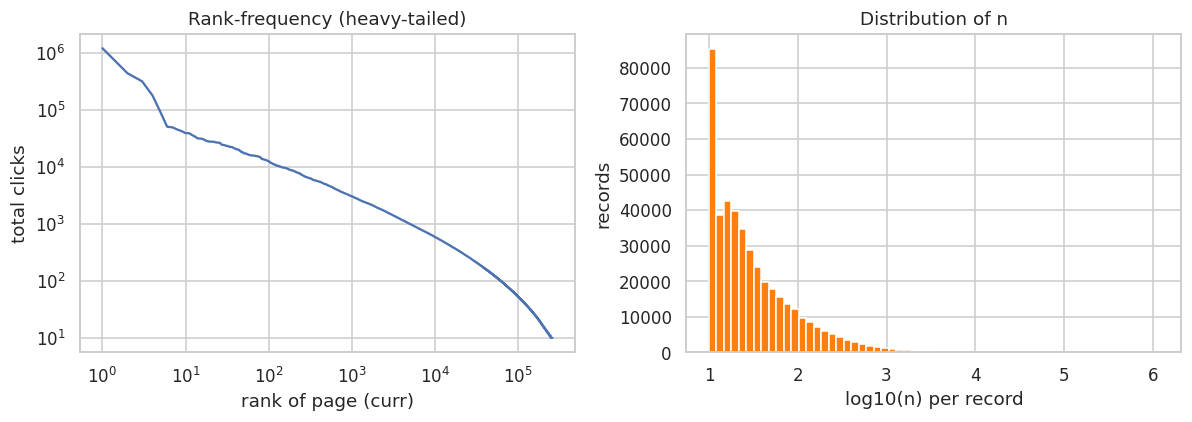

상위 1% 페이지가 전체 클릭의 33.0% 차지


In [26]:
# 데이터 특성 시각화: 순위-빈도(Zipf), 레코드별 n 분포
cnts_sorted = np.array(sorted(true_cnt.values(), reverse=True))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(np.arange(1, len(cnts_sorted)+1), cnts_sorted, lw=1.5)
ax[0].set_xlabel('rank of page (curr)'); ax[0].set_ylabel('total clicks'); ax[0].set_title('Rank-frequency (heavy-tailed)')
ax[1].hist(np.log10(n_seq), bins=60, color='tab:orange')
ax[1].set_xlabel('log10(n) per record'); ax[1].set_ylabel('records'); ax[1].set_title('Distribution of n')
savefig('fig01_dataset.png')

top1pct = cnts_sorted[:max(1, len(cnts_sorted)//100)].sum() / cnts_sorted.sum()
print(f'상위 1% 페이지가 전체 클릭의 {top1pct*100:.1f}% 차지')

## 2. 알고리즘 구현 (순수 Python)
### 해시 설계
- 키 하나당 `blake2b(digest_size=64, salt=seed)` **1회 호출** --> 64바이트를 32비트 정수 16개로 분해한다.
- Bloom Filter 의 k개 위치, CMS 의 d개 행 인덱스는 각각 **서로 독립인 32비트 조각** 을 사용한다 (`value % m`).
  (이중 해싱 `h1 + i·h2` 은 두 키가 앞의 두 행에서 충돌하면 모든 행에서 충돌하는 약점이 있어, CMS 의 depth 효과를 왜곡할 수 있으므로 사용하지 않았다.)
- HyperLogLog 는 같은 digest 의 앞 8바이트를 64비트 해시로 사용한다.
- 같은 digest 규칙을 **numpy 벡터화 구현**에서도 그대로 사용해, 스트리밍 구현과 결과가 비트 단위로 같음을 §4 에서 검증한다.

In [27]:
_U32 = struct.Struct('<16I')

def make_digest(seed):
    salt = int(seed).to_bytes(8, 'little')
    b2 = hashlib.blake2b
    def digest(key):
        return b2(key.encode('utf-8'), digest_size=64, salt=salt).digest()
    return digest

# ============================ Bloom Filter ============================
class BloomFilter:
    # 비트 배열 m 비트, 해시 k개. 삽입 시 k개 비트를 1로, 질의 시 k개가 모두 1이면 '있을 수 있음'
    def __init__(self, m, k, seed=0):
        assert 1 <= k <= 16
        self.m, self.k = int(m), int(k)
        self.bits = bytearray((self.m + 7) // 8)
        self.digest = make_digest(seed)
        self.n_added = 0
    def add(self, key):
        bits, m = self.bits, self.m
        for v in _U32.unpack(self.digest(key))[:self.k]:
            j = v % m
            bits[j >> 3] |= 1 << (j & 7)
        self.n_added += 1
    def __contains__(self, key):
        bits, m = self.bits, self.m
        for v in _U32.unpack(self.digest(key))[:self.k]:
            j = v % m
            if not (bits[j >> 3] >> (j & 7)) & 1:
                return False
        return True
    @property
    def nbytes(self): return len(self.bits)
    def theoretical_fpr(self, n=None):
        n = self.n_added if n is None else n
        return (1.0 - math.exp(-self.k * n / self.m)) ** self.k

def bloom_design(n, p):
    # 목표 FPR p, 원소 n개일 때의 최적 (m, k)
    m = math.ceil(-n * math.log(p) / (math.log(2) ** 2))
    k = max(1, round(m / n * math.log(2)))
    return m, k

# ======================== Count-Min Sketch ============================
class CountMinSketch:
    # d x w 카운터 표. update: 각 행의 한 칸에 += c, query: d개 칸의 min.  conservative=True 이면 CU(보수적 갱신)
    def __init__(self, width, depth, seed=0, conservative=False):
        assert 1 <= depth <= 16
        self.w, self.d = int(width), int(depth)
        self.conservative = conservative
        self.digest = make_digest(seed)
        self.tables = [array('I', bytes(4 * self.w)) for _ in range(self.d)]   # uint32 카운터
        assert self.tables[0].itemsize == 4
        self.total = 0
    def update(self, key, c=1):
        w, d, tabs = self.w, self.d, self.tables
        vals = _U32.unpack(self.digest(key))
        self.total += c
        if not self.conservative:
            est = None
            for i in range(d):
                t = tabs[i]; j = vals[i] % w
                v = t[j] + c; t[j] = v
                if est is None or v < est: est = v
            return est
        js = [vals[i] % w for i in range(d)]
        new = min(tabs[i][js[i]] for i in range(d)) + c
        for i in range(d):
            if tabs[i][js[i]] < new: tabs[i][js[i]] = new
        return new
    def query(self, key):
        w, tabs = self.w, self.tables
        vals = _U32.unpack(self.digest(key))
        return min(tabs[i][vals[i] % w] for i in range(self.d))
    @property
    def nbytes(self): return self.w * self.d * 4

class TopKTracker:
    # 스트리밍 중 CMS 추정값으로 상위 K개 후보를 유지 (heavy hitter 탐지)
    def __init__(self, K):
        self.K, self.d, self.thr = K, {}, -1
    def offer(self, key, est):
        d = self.d
        if key in d:
            d[key] = est
        elif len(d) < self.K:
            d[key] = est
        elif est > self.thr:
            mk = min(d, key=d.get)
            if est > d[mk]:
                del d[mk]; d[key] = est
            self.thr = min(d.values())
    def keys(self): return set(self.d)

# ========================== HyperLogLog ===============================
def _alpha(m):
    return {16: 0.673, 32: 0.697, 64: 0.709}.get(m, 0.7213 / (1 + 1.079 / m))

def hll_estimate_classic(reg, p):
    # Flajolet et al. (2007): 조화평균 + 소규모 구간 Linear Counting 보정 (64비트 해시라 대규모 보정 불필요)
    m = 1 << p
    reg = np.asarray(reg)
    E = _alpha(m) * m * m / np.sum(np.ldexp(1.0, -reg.astype(np.int64)))
    V = int(np.count_nonzero(reg == 0))
    if E <= 2.5 * m and V > 0:
        E = m * math.log(m / V)
    return E

def _sigma(x):
    if x == 1.0: return math.inf
    y, z = 1.0, x
    while True:
        x *= x; zp = z; z += x * y; y += y
        if z == zp: return z
def _tau(x):
    if x == 0.0 or x == 1.0: return 0.0
    y, z = 1.0, 1.0 - x
    while True:
        x = math.sqrt(x); zp = z; y *= 0.5; z -= (1.0 - x) ** 2 * y
        if z == zp: return z / 3.0

def hll_estimate_improved(reg, p):
    # Ertl (2017) 개선 추정기: 경험적 bias 표 없이 전 구간에서 정확 (레지스터 값 히스토그램 기반)
    m, q = 1 << p, 64 - p
    C = np.bincount(np.asarray(reg).astype(np.int64), minlength=q + 2)
    z = m * _tau(1.0 - C[q + 1] / m)
    for k in range(q, 0, -1):
        z = 0.5 * (z + C[k])
    z += m * _sigma(C[0] / m)
    return (1.0 / (2.0 * math.log(2))) * m * m / z

class HyperLogLog:
    # 해시 64비트 = [상위 p비트: 레지스터 번호 | 하위 q=64-p 비트: 선행 0의 개수+1 (rho)]. 레지스터는 rho 의 최댓값 유지
    def __init__(self, p, seed=0):
        assert 4 <= p <= 18
        self.p, self.m, self.q = p, 1 << p, 64 - p
        self.reg = bytearray(self.m)
        self.digest = make_digest(seed)
        self._qmask = (1 << self.q) - 1
    def add(self, key):
        x = int.from_bytes(self.digest(key)[:8], 'little')
        j = x >> self.q
        rho = self.q - (x & self._qmask).bit_length() + 1
        if rho > self.reg[j]: self.reg[j] = rho
    def merge(self, other):
        assert self.p == other.p
        self.reg = bytearray(max(a, b) for a, b in zip(self.reg, other.reg))   # 레지스터별 max -> 합집합 sketch
    def estimate(self, method='improved'):
        f = hll_estimate_improved if method == 'improved' else hll_estimate_classic
        return f(np.frombuffer(self.reg, dtype=np.uint8), self.p)
    @property
    def nbytes(self): return self.m                      # 구현: 레지스터당 1바이트
    @property
    def nbytes_packed(self): return math.ceil(self.m * 6 / 8)   # 이론: 레지스터당 6비트

# ---- 간단한 정상 동작 확인 ----
_h = HyperLogLog(10); [ _h.add(f'k{i}') for i in range(50_000) ]
print('HLL sanity (true 50,000): classic %.0f / improved %.0f' % (_h.estimate('classic'), _h.estimate('improved')))
_b = BloomFilter(100_000, 5); [ _b.add(f'x{i}') for i in range(10_000) ]
print('Bloom sanity: all inserted found =', all(f'x{i}' in _b for i in range(10_000)))
_c = CountMinSketch(1024, 4); [ _c.update('a', 3) for _ in range(10) ]; print('CMS sanity: query(a) =', _c.query('a'), '(true 30)')

HLL sanity (true 50,000): classic 50371 / improved 50427
Bloom sanity: all inserted found = True
CMS sanity: query(a) = 30 (true 30)


## 3. 메인 실험 (스트리밍 실행)
기본 파라미터: Bloom (목표 FPR 1% → m, k 자동 설계), CMS (width 8192 × depth 5), HLL (p = 14).
먼저 **처리 시간** (파일 읽기·파싱 포함 end-to-end 와, 파싱 시간을 뺀 net 처리량), 다음 **메모리**, 마지막으로 **정확도** 를 측정한다.

In [28]:
M_BLOOM, K_BLOOM = bloom_design(N_INSERT, BLOOM_TARGET_FPR)
print(f'Bloom 설계: n={N_INSERT:,}, 목표 FPR={BLOOM_TARGET_FPR} -> m={M_BLOOM:,} bits ({M_BLOOM/8/1024:.0f} KiB, {M_BLOOM/N_INSERT:.2f} bits/elem), k={K_BLOOM}')
print(f'CMS: width={CMS_W}, depth={CMS_D}, eps=e/w={math.e/CMS_W:.2e}, delta=e^-d={math.exp(-CMS_D):.4f}, eps*N={math.e/CMS_W*TOTAL_CLICKS:,.0f}')
print(f'HLL: p={HLL_P}, m={1<<HLL_P}, 이론 표준오차 1.04/sqrt(m)={1.04/math.sqrt(1<<HLL_P)*100:.2f}%')

# ---------- 각 패스: 파일을 처음부터 한 줄씩 읽으며 처리 ----------
def parse_only():
    for _ in stream_rows(): pass

def hash_only():
    dg = make_digest(SEED)
    for p, c, t, n in stream_rows(): dg(c)

def bloom_insert():
    bf = BloomFilter(M_BLOOM, K_BLOOM, SEED)
    for p, c, t, n in itertools.islice(stream_rows(), N_INSERT):
        bf.add(p + '\t' + c)
    return bf

def bloom_query(bf):
    fp = q = 0
    for p, c, t, n in itertools.islice(stream_rows(), N_INSERT, None):
        q += 1
        if (p + '\t' + c) in bf: fp += 1
    return fp, q

def set_insert():
    s = set()
    for p, c, t, n in itertools.islice(stream_rows(), N_INSERT): s.add(p + '\t' + c)
    return s

def set_query(s):
    hit = 0
    for p, c, t, n in itertools.islice(stream_rows(), N_INSERT, None):
        if (p + '\t' + c) in s: hit += 1
    return hit

def cms_pass(conservative=False, tracker=None):
    cms = CountMinSketch(CMS_W, CMS_D, SEED, conservative)
    if tracker is None:
        for p, c, t, n in stream_rows(): cms.update(c, n)
    else:
        for p, c, t, n in stream_rows(): tracker.offer(c, cms.update(c, n))
    return cms

def counter_pass():
    d = {}
    for p, c, t, n in stream_rows(): d[c] = d.get(c, 0) + n
    return d

def hll_pass(field='curr'):
    h = HyperLogLog(HLL_P, SEED)
    if field == 'curr':
        for p, c, t, n in stream_rows(): h.add(c)
    elif field == 'prev':
        for p, c, t, n in stream_rows(): h.add(p)
    else:
        for p, c, t, n in stream_rows(): h.add(p + '\t' + c)
    return h

def set_pass(field='curr'):
    s = set()
    if field == 'curr':
        for p, c, t, n in stream_rows(): s.add(c)
    elif field == 'prev':
        for p, c, t, n in stream_rows(): s.add(p)
    else:
        for p, c, t, n in stream_rows(): s.add(p + '\t' + c)
    return s

def bench(fn, *args, repeats=TIMING_REPEATS):
    ts, out = [], None
    for _ in range(repeats):
        gc.collect(); t0 = time.perf_counter()
        out = fn(*args)
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out

t_parse, _ = bench(parse_only)
t_hash,  _ = bench(hash_only)
print(f'파싱만(파일 읽기+split): {t_parse:.2f}s  ({N_ROWS/t_parse:,.0f} rows/s)')
print(f'파싱+해시만:            {t_hash:.2f}s')

timing_rows = []
def record(name, group, t, rows):
    share = t_parse * rows / N_ROWS
    timing_rows.append(dict(structure=name, group=group, rows=rows, seconds=t, rows_per_s=rows/t,
                            net_rows_per_s=rows/max(t-share, 1e-9)))

t, bf_main = bench(bloom_insert);                       record('Bloom insert', 'sketch', t, N_INSERT)
t, _       = bench(lambda: bloom_query(bf_main));      record('Bloom query',  'sketch', t, N_ROWS-N_INSERT)
t, _       = bench(cms_pass);                          record('CMS update (standard)', 'sketch', t, N_ROWS)
t, _       = bench(cms_pass, True);                    record('CMS update (conservative)', 'sketch', t, N_ROWS)
t, _       = bench(hll_pass, 'curr');                  record('HLL add', 'sketch', t, N_ROWS)
t, set_main = bench(set_insert);                        record('set insert (exact)', 'exact', t, N_INSERT)
t, _       = bench(lambda: set_query(set_main));       record('set query (exact)',  'exact', t, N_ROWS-N_INSERT)
t, _       = bench(counter_pass);                      record('dict count (exact)', 'exact', t, N_ROWS)
t, _       = bench(set_pass, 'curr');                  record('set distinct (exact)', 'exact', t, N_ROWS)
df_time = pd.DataFrame(timing_rows)
df_time['seconds'] = df_time['seconds'].round(3)
df_time[['rows_per_s','net_rows_per_s']] = df_time[['rows_per_s','net_rows_per_s']].round(0)
df_time.to_csv(os.path.join(OUT_DIR, 'timing_main.csv'), index=False)
df_time

Bloom 설계: n=300,000, 목표 FPR=0.01 -> m=2,875,518 bits (351 KiB, 9.59 bits/elem), k=7
CMS: width=8192, depth=5, eps=e/w=3.32e-04, delta=e^-d=0.0067, eps*N=12,311
HLL: p=14, m=16384, 이론 표준오차 1.04/sqrt(m)=0.81%
파싱만(파일 읽기+split): 0.42s  (1,011,972 rows/s)
파싱+해시만:            0.91s


,structure,group,rows,seconds,rows_per_s,net_rows_per_s
0,Bloom insert,sketch,300000,2,"190,178","234,188"
1,Bloom query,sketch,130068,1,"169,091","203,012"
2,CMS update (standard),sketch,430068,2,"212,236","268,560"
3,CMS update (conservative),sketch,430068,3,"170,016","204,348"
4,HLL add,sketch,430068,1,"292,440","411,296"
5,set insert (exact),exact,300000,0,"660,860","1,904,722"
6,set query (exact),exact,130068,0,"270,929","369,982"
7,dict count (exact),exact,430068,1,"670,746","1,989,225"
8,set distinct (exact),exact,430068,1,"766,744","3,164,086"


### 3.2 메모리
- **이론 크기**: 자료구조가 차지하는 바이트 (비트 배열 길이, 카운터 수×4바이트, 레지스터 수).
- **tracemalloc 실측**: 스트림을 모두 처리한 뒤 *남아 있는* Python 객체의 총 바이트(`current`)와 처리 중 최대치(`peak`).
- Ground Truth 의 `set`/`dict` 는 Python 문자열 객체까지 모두 보관하므로 훨씬 크다. 그것이 근사 알고리즘을 쓰는 이유입니다.

In [29]:
def measure(builder, *args):
    gc.collect(); tracemalloc.start()
    base = tracemalloc.get_traced_memory()[0]
    obj = builder(*args)
    gc.collect()
    cur, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return obj, cur - base, peak - base

mem_rows = []
def mrec(name, kind, theory, cur, peak):
    mem_rows.append(dict(structure=name, kind=kind, theoretical_bytes=theory, tracemalloc_retained=cur, tracemalloc_peak=peak))

bf, cur, peak = measure(bloom_insert);        mrec('Bloom Filter', 'sketch', bf.nbytes, cur, peak)
s_, cur, peak = measure(set_insert);          mrec('set of pairs (exact)', 'exact', sys.getsizeof(s_), cur, peak)
cm, cur, peak = measure(cms_pass);            mrec('Count-Min Sketch', 'sketch', cm.nbytes, cur, peak)
d_, cur, peak = measure(counter_pass);        mrec('dict of page counts (exact)', 'exact', sys.getsizeof(d_), cur, peak)
hl, cur, peak = measure(hll_pass, 'curr');    mrec('HyperLogLog (1 byte/reg)', 'sketch', hl.nbytes, cur, peak)
mrec('HyperLogLog (6-bit packed, theory)', 'sketch', hl.nbytes_packed, np.nan, np.nan)
s2, cur, peak = measure(set_pass, 'curr');    mrec('set of pages (exact)', 'exact', sys.getsizeof(s2), cur, peak)
del s_, d_, s2
df_mem = pd.DataFrame(mem_rows)
df_mem.to_csv(os.path.join(OUT_DIR, 'memory_main.csv'), index=False)

EXACT_MEM = {
    'bloom': float(df_mem.loc[df_mem.structure=='set of pairs (exact)', 'tracemalloc_retained'].iloc[0]),
    'cms':   float(df_mem.loc[df_mem.structure=='dict of page counts (exact)', 'tracemalloc_retained'].iloc[0]),
    'hll':   float(df_mem.loc[df_mem.structure=='set of pages (exact)', 'tracemalloc_retained'].iloc[0]),
}
pd.options.display.float_format = '{:,.0f}'.format
print('메모리 감소율(실측, exact 대비 sketch 비율)')
print(f"  Bloom : {bf.nbytes/EXACT_MEM['bloom']*100:.2f}%   ({EXACT_MEM['bloom']/bf.nbytes:,.0f}x 작음)")
print(f"  CMS   : {cm.nbytes/EXACT_MEM['cms']*100:.2f}%   ({EXACT_MEM['cms']/cm.nbytes:,.0f}x 작음)")
print(f"  HLL   : {hl.nbytes/EXACT_MEM['hll']*100:.3f}%  ({EXACT_MEM['hll']/hl.nbytes:,.0f}x 작음)")
df_mem

메모리 감소율(실측, exact 대비 sketch 비율)
  Bloom : 0.98%   (102x 작음)
  CMS   : 0.61%   (165x 작음)
  HLL   : 0.061%  (1,638x 작음)


,structure,kind,theoretical_bytes,tracemalloc_retained,tracemalloc_peak
0,Bloom Filter,sketch,359440,"360,690","425,376"
1,set of pairs (exact),exact,8388824,"36,815,713","36,853,377"
2,Count-Min Sketch,sketch,163840,"175,352","240,110"
3,dict of page counts (exact),exact,7689648,"26,958,811","27,005,289"
4,HyperLogLog (1 byte/reg),sketch,16384,"17,197","81,787"
5,"HyperLogLog (6-bit packed, theory)",sketch,12288,NaN,NaN
6,set of pages (exact),exact,8388824,"26,835,619","26,882,041"


### 3.3 정확도 (시드 0, 스트리밍 구현)
- **Bloom**: 삽입하지 않은 130k개 pair 질의 → FPR (이론식 `(1-e^{-kn/m})^k` 와 비교), 삽입한 300k개 전부 질의 → FNR (0 이어야 함)
- **CMS**: 모든 고유 페이지(약 26만 개)의 추정값 vs 정확한 빈도. 상위 100 / 101~10,000 / 그 아래(꼬리) 구간별 상대오차, `εN` 상한 만족 비율, 스트리밍 Top-100 탐지 정확도
- **HLL**: 고유 `curr`, `prev`, `prev→curr` 수의 상대오차 (classic vs improved 추정기)

In [30]:
# ---------------- Bloom ----------------
fp, q = bloom_query(bf)
fpr_emp = fp / q
fpr_theory = bf.theoretical_fpr()
fn = sum(1 for key in pairs[:N_INSERT] if key not in bf)
bloom_main = dict(m=M_BLOOM, k=K_BLOOM, n=N_INSERT, queries=q, false_positives=fp,
                  fpr_empirical=fpr_emp, fpr_theory=fpr_theory, false_negatives=fn,
                  bits_per_elem=M_BLOOM/N_INSERT, bytes=bf.nbytes,
                  fill_ratio=float(np.unpackbits(np.frombuffer(bf.bits, np.uint8)).sum() / M_BLOOM))
print(json.dumps(bloom_main, indent=1))

# ---------------- CMS ----------------
U_curr = list(true_cnt.keys())
counts = np.array([true_cnt[k] for k in U_curr], dtype=np.float64)
order  = np.argsort(-counts, kind='stable')
head_idx, torso_idx, tail_idx = order[:100], order[100:10_000], order[10_000:]

tk = TopKTracker(TOPK)
cms_tk = cms_pass(False, tk)                       # 추적기 포함 패스 (정확도용)
est = np.array([cms_tk.query(k) for k in U_curr], dtype=np.float64)
err = est - counts
assert (err >= 0).all(), 'CMS 는 과소추정이 없어야 함'
rel = err / counts
eps_N = math.e / CMS_W * TOTAL_CLICKS
true_top = {k for k, _ in true_cnt.most_common(TOPK)}
cms_main = dict(width=CMS_W, depth=CMS_D, bytes=cms_tk.nbytes, N=TOTAL_CLICKS, eps_N=eps_N,
                underestimates=int((err < 0).sum()),
                rel_err_top100=float(rel[head_idx].mean()), rel_err_101_10000=float(rel[torso_idx].mean()),
                rel_err_tail=float(rel[tail_idx].mean()), median_rel_err_tail=float(np.median(rel[tail_idx])),
                mean_abs_err_all=float(err.mean()),
                frac_err_le_epsN=float((err <= eps_N).mean()), delta_theory=math.exp(-CMS_D),
                top100_precision_streaming=len(tk.keys() & true_top)/TOPK)
print(json.dumps(cms_main, indent=1))

# ---------------- HLL ----------------
hll_main = {}
for field, truth in [('curr', len(set_curr)), ('prev', len(set_prev)), ('pair', len(set_pairs_all))]:
    h = hll_pass(field)
    ec, ei = h.estimate('classic'), h.estimate('improved')
    hll_main[field] = dict(true=truth, classic=ec, improved=ei,
                           rel_err_classic=(ec-truth)/truth, rel_err_improved=(ei-truth)/truth)
print(pd.DataFrame(hll_main).T.to_string(float_format=lambda x: f'{x:,.4f}' if abs(x)<10 else f'{x:,.0f}'))
print(f'p={HLL_P} 이론 표준오차: {1.04/math.sqrt(1<<HLL_P)*100:.2f}%')

{
 "m": 2875518,
 "k": 7,
 "n": 300000,
 "queries": 130068,
 "false_positives": 1320,
 "fpr_empirical": 0.010148537687978595,
 "fpr_theory": 0.010039209581758123,
 "false_negatives": 0,
 "bits_per_elem": 9.58506,
 "bytes": 359440,
 "fill_ratio": 0.518023883001254
}
{
 "width": 8192,
 "depth": 5,
 "bytes": 163840,
 "N": 37100041,
 "eps_N": 12310.591709641789,
 "underestimates": 0,
 "rel_err_top100": 0.10050610426606374,
 "rel_err_101_10000": 2.0341806033541157,
 "rel_err_tail": 78.24458779939988,
 "median_rel_err_tail": 57.32258064516129,
 "mean_abs_err_all": 2059.784273975147,
 "frac_err_le_epsN": 1.0,
 "delta_theory": 0.006737946999085467,
 "top100_precision_streaming": 0.98
}
        true  classic  improved  rel_err_classic  rel_err_improved
curr 258,476  262,095   262,130           0.0140            0.0141
prev  35,485   35,221    35,278          -0.0074           -0.0058
pair 430,068  425,267   425,323          -0.0112           -0.0110
p=14 이론 표준오차: 0.81%


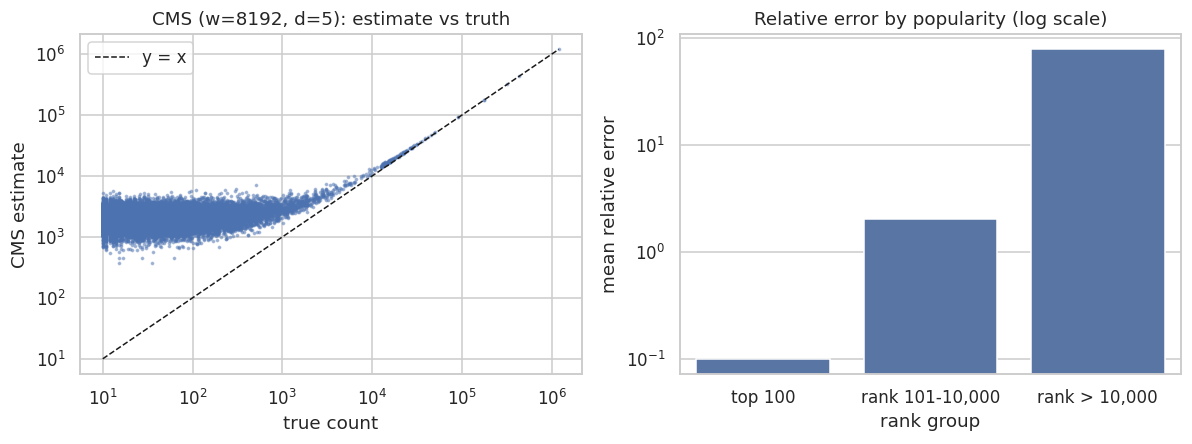

In [31]:
# CMS 시각화: 추정값 vs 진짜값, 순위 구간별 상대오차
rng = np.random.default_rng(0)
samp = np.concatenate([head_idx, rng.choice(len(U_curr), 20_000, replace=False)])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].loglog(counts[samp], est[samp], '.', ms=3, alpha=.4)
lo, hi = counts.min(), counts.max()
ax[0].loglog([lo, hi], [lo, hi], 'k--', lw=1, label='y = x')
ax[0].set_xlabel('true count'); ax[0].set_ylabel('CMS estimate'); ax[0].legend()
ax[0].set_title(f'CMS (w={CMS_W}, d={CMS_D}): estimate vs truth')
grp = pd.DataFrame({'rank group': np.select([np.isin(np.arange(len(U_curr)), head_idx), np.isin(np.arange(len(U_curr)), torso_idx)],
                                            ['top 100', 'rank 101-10,000'], 'rank > 10,000'), 'rel_err': rel})
sns.barplot(data=grp, x='rank group', y='rel_err', order=['top 100','rank 101-10,000','rank > 10,000'], ax=ax[1], errorbar=None)
ax[1].set_yscale('log'); ax[1].set_ylabel('mean relative error'); ax[1].set_title('Relative error by popularity (log scale)')
savefig('fig02_cms_main.png')

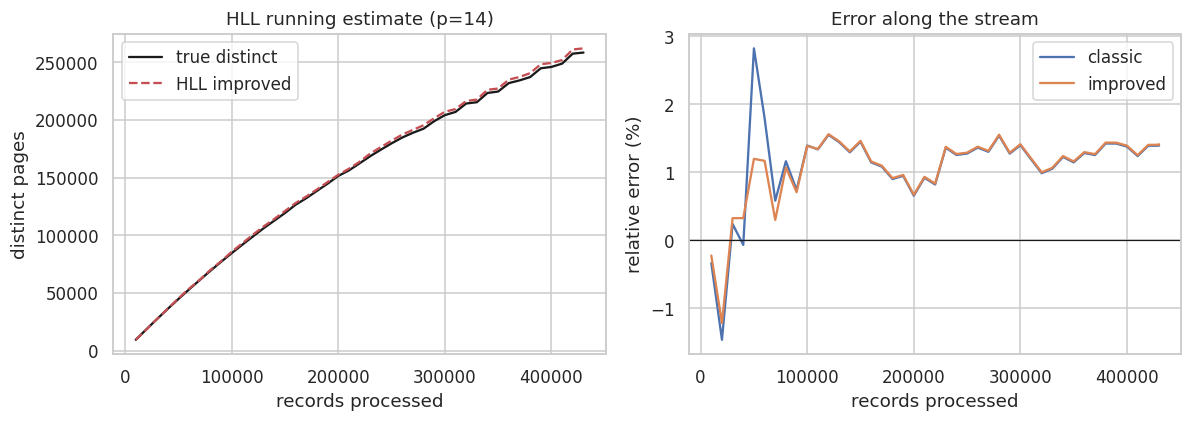

merge(앞절반, 뒤절반) == 전체 sketch : True


In [32]:
# HLL 러닝 추정: 스트림이 진행됨에 따라 추정값이 실제 고유 수를 따라가는지 (p=14)
h = HyperLogLog(HLL_P, SEED); marks = dict(distinct_curr_at); running = []
for i, (p, c, t, n) in enumerate(stream_rows(), 1):
    h.add(c)
    if i in marks: running.append((i, marks[i], h.estimate('classic'), h.estimate('improved')))
df_run = pd.DataFrame(running, columns=['rows', 'true', 'classic', 'improved'])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(df_run.rows, df_run.true, 'k-', label='true distinct'); ax[0].plot(df_run.rows, df_run.improved, 'r--', label='HLL improved')
ax[0].set_xlabel('records processed'); ax[0].set_ylabel('distinct pages'); ax[0].legend(); ax[0].set_title('HLL running estimate (p=14)')
ax[1].plot(df_run.rows, (df_run.classic/df_run.true-1)*100, label='classic'); ax[1].plot(df_run.rows, (df_run.improved/df_run.true-1)*100, label='improved')
ax[1].axhline(0, color='k', lw=.8); ax[1].set_xlabel('records processed'); ax[1].set_ylabel('relative error (%)'); ax[1].legend(); ax[1].set_title('Error along the stream')
savefig('fig03_hll_running.png')

# HLL 의 merge: 앞 절반/뒤 절반을 따로 만든 sketch 를 합치면 전체 sketch 와 동일 (분산 처리 가능)
hA, hB, hAll = HyperLogLog(HLL_P, SEED), HyperLogLog(HLL_P, SEED), HyperLogLog(HLL_P, SEED)
for i, c in enumerate(curr_seq):
    (hA if i < N_ROWS//2 else hB).add(c); hAll.add(c)
hA.merge(hB); print('merge(앞절반, 뒤절반) == 전체 sketch :', hA.reg == hAll.reg)

## 4. 벡터화 복제 구현과 동치 검증
파라미터 스윕은 설정이 수백 개라 스트리밍 Python 루프로는 오래 걸린다. 그래서 **같은 해시 규칙을 쓰는 numpy 벡터화 구현**으로 스윕을 수행한다.
- Bloom: 비트 배열에 위치를 한꺼번에 기록 (삽입은 순서와 무관)
- CMS: 표준 CMS 는 **선형(linear)** 이라 순서와 무관 → `bincount` 로 동일한 표 생성
- HLL: 레지스터는 `max` 연산이라 순서 무관

아래에서 **스트리밍 구현의 내부 상태(비트·카운터·레지스터)가 벡터화 구현과 완전히 같은지** 확인한다.

In [33]:
def digest_matrix(keys, seed):
    salt = int(seed).to_bytes(8, 'little'); b2 = hashlib.blake2b
    buf = b''.join([b2(k.encode('utf-8'), digest_size=64, salt=salt).digest() for k in keys])
    return np.frombuffer(buf, dtype='<u4').reshape(len(keys), 16)

def bloom_bits_vec(D, m, k, ins):
    P = D[:ins, :k] % np.uint32(m)
    bits = np.zeros(m, dtype=bool); bits[P.ravel()] = True
    return bits

def cms_tables_vec(D, weights, w, d):
    tabs = []
    for i in range(d):
        idx = D[:, i] % np.uint32(w)
        tabs.append(np.bincount(idx, weights=weights, minlength=w))
    return tabs

def hll_x(D):
    return D[:, 0].astype(np.uint64) | (D[:, 1].astype(np.uint64) << np.uint64(32))

def hll_registers_vec(x, p):
    q = 64 - p
    idx = (x >> np.uint64(q)).astype(np.int64)
    w = x & np.uint64((1 << q) - 1)
    hi = (w >> np.uint64(32)).astype(np.float64); lo = (w & np.uint64(0xFFFFFFFF)).astype(np.float64)
    bitlen = np.where(hi > 0, 32 + np.frexp(hi)[1], np.frexp(lo)[1])       # 정확한 bit_length (32비트씩 나눠 계산)
    rho = (q - bitlen + 1).astype(np.uint8)
    reg = np.zeros(1 << p, dtype=np.uint8); np.maximum.at(reg, idx, rho)
    return reg

# ---- 동치 검증 (메인 파라미터, 시드 0) ----
D_pairs = digest_matrix(pairs, SEED)
bits_v = bloom_bits_vec(D_pairs, M_BLOOM, K_BLOOM, N_INSERT)
bits_s = np.unpackbits(np.frombuffer(bf.bits, np.uint8), bitorder='little')[:M_BLOOM].astype(bool)
print('Bloom 비트 배열 동일  :', np.array_equal(bits_v, bits_s))

D_curr = digest_matrix(U_curr, SEED)
tabs_v = cms_tables_vec(D_curr, counts, CMS_W, CMS_D)
print('CMS 카운터 표 동일    :', all(np.array_equal(np.array(cm.tables[i], dtype=np.float64), tabs_v[i]) for i in range(CMS_D)))

reg_v = hll_registers_vec(hll_x(D_curr), HLL_P)
print('HLL 레지스터 동일     :', np.array_equal(np.frombuffer(hl.reg, np.uint8), reg_v))

Bloom 비트 배열 동일  : True
CMS 카운터 표 동일    : True
HLL 레지스터 동일     : True


## 5. 파라미터 비교 실험 (선택 과제)
각 설정마다 **시드를 바꿔 반복**(Bloom/CMS 5회, HLL 20회)하여 평균과 표준편차를 구한다.

### 5.1 Bloom Filter: 비트 수(bits/element) × 해시 개수 k
- bits/element 는 `m / n` (n=300,000). 이론 최적 k 는 `(m/n)·ln2`.
- 이론 FPR 과 실측 FPR 을 비교하고, **k 를 최적값 이상으로 올리면 오히려 FPR 이 나빠지는지** 확인한다.

In [34]:
BITS_PER_ELEM = [2, 3, 4, 6, 8, 10, 12, 16, 20]
KS = list(range(1, 17))
rows = []
for seed in SWEEP_SEEDS:
    D = D_pairs if seed == SEED else digest_matrix(pairs, seed)
    for b in BITS_PER_ELEM:
        m = int(b * N_INSERT)
        Pm = D % np.uint32(m)
        for k in KS:
            P = Pm[:, :k]
            bits = np.zeros(m, dtype=bool); bits[P[:N_INSERT].ravel()] = True
            fpr = bits[P[N_INSERT:]].all(axis=1).mean()
            fnr = 1.0 - bits[P[:N_INSERT]].all(axis=1).mean()
            rows.append(dict(seed=seed, bits_per_elem=b, m=m, k=k, fpr=fpr, fnr=fnr,
                             fpr_theory=(1 - math.exp(-k * N_INSERT / m)) ** k, bytes=m // 8, fill=bits.mean()))
df_bloom = pd.DataFrame(rows)
df_bloom.to_csv(os.path.join(OUT_DIR, 'bloom_sweep_raw.csv'), index=False)
g = df_bloom.groupby(['bits_per_elem', 'k']).agg(fpr_mean=('fpr', 'mean'), fpr_std=('fpr', 'std'),
        fpr_theory=('fpr_theory', 'first'), fnr_max=('fnr', 'max'), bytes=('bytes', 'first'), fill=('fill', 'mean')).reset_index()
g.to_csv(os.path.join(OUT_DIR, 'bloom_sweep.csv'), index=False)
print('FNR 최댓값(전 설정):', g.fnr_max.max(), '  <- Bloom Filter 는 False Negative 가 없어야 함')

best = g.loc[g.groupby('bits_per_elem').fpr_mean.idxmin()][['bits_per_elem', 'k', 'fpr_mean', 'fpr_theory', 'bytes']].copy()
best['k_opt_theory'] = (best.bits_per_elem * math.log(2)).round(1)
pd.options.display.float_format = '{:,.6f}'.format
print('각 bits/element 에서 FPR 이 최소인 k (실측) 와 이론 최적 k')
best

FNR 최댓값(전 설정): 0.0   <- Bloom Filter 는 False Negative 가 없어야 함
각 bits/element 에서 FPR 이 최소인 k (실측) 와 이론 최적 k


,bits_per_elem,k,fpr_mean,fpr_theory,bytes,k_opt_theory
0,2,1,0.392868,0.393469,75000,1.400000
17,3,2,0.236905,0.236763,112500,2.100000
34,4,3,0.145967,0.146892,150000,2.800000
51,6,4,0.055611,0.056057,225000,4.200000
68,8,5,0.021566,0.021679,300000,5.500000
86,10,7,0.008120,0.008194,375000,6.900000
103,12,8,0.003206,0.003142,450000,8.300000
123,16,12,0.000403,0.000466,600000,11.100000
140,20,13,0.000052,0.000068,750000,13.900000


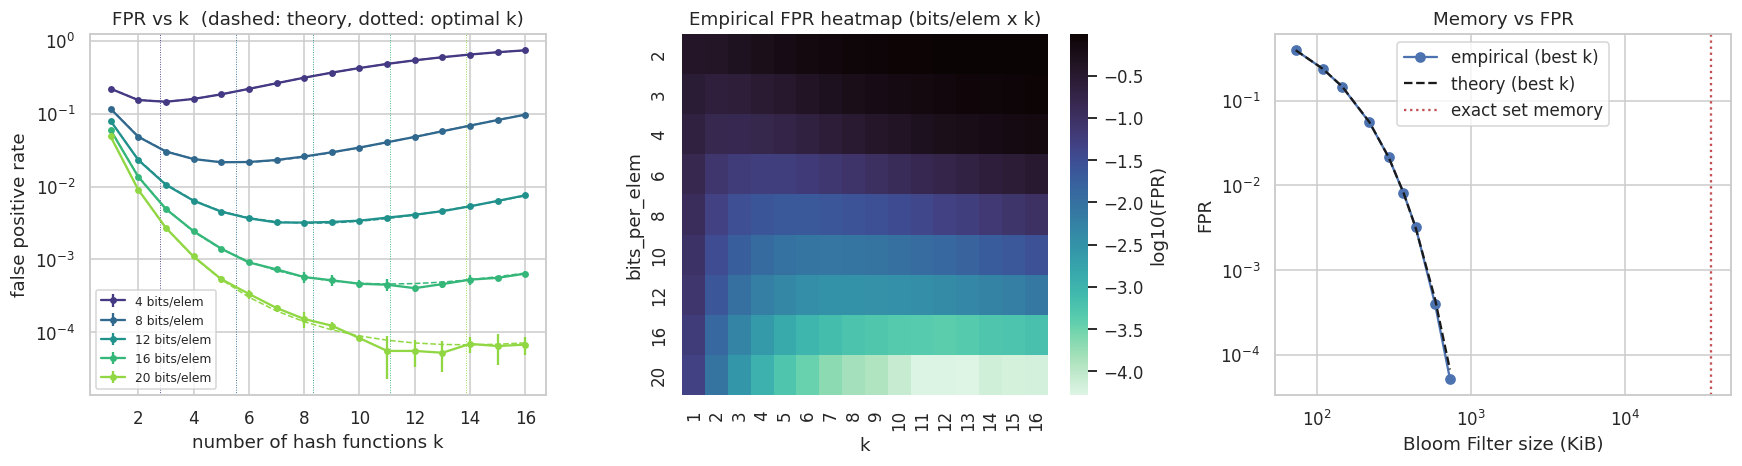

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
pal = sns.color_palette('viridis', 5)
for c, b in zip(pal, [4, 8, 12, 16, 20]):
    s = g[g.bits_per_elem == b]
    ax[0].errorbar(s.k, s.fpr_mean, yerr=s.fpr_std, fmt='o-', ms=3.5, color=c, label=f'{b} bits/elem')
    ax[0].plot(s.k, s.fpr_theory, '--', color=c, lw=1)
    ax[0].axvline(b*math.log(2), color=c, lw=.6, ls=':')
ax[0].set_yscale('log'); ax[0].set_xlabel('number of hash functions k'); ax[0].set_ylabel('false positive rate')
ax[0].set_title('FPR vs k  (dashed: theory, dotted: optimal k)'); ax[0].legend(fontsize=8)

piv = g.pivot(index='bits_per_elem', columns='k', values='fpr_mean')
sns.heatmap(np.log10(piv), ax=ax[1], cmap='mako_r', cbar_kws={'label': 'log10(FPR)'}, annot=False)
ax[1].set_title('Empirical FPR heatmap (bits/elem x k)')

bb = best.copy(); bb['theory_min'] = [g[(g.bits_per_elem==b)].fpr_theory.min() for b in bb.bits_per_elem]
ax[2].loglog(bb.bytes/1024, bb.fpr_mean, 'o-', label='empirical (best k)')
ax[2].loglog(bb.bytes/1024, bb.theory_min, 'k--', label='theory (best k)')
ax[2].axvline(EXACT_MEM['bloom']/1024, color='r', ls=':', label='exact set memory')
ax[2].set_xlabel('Bloom Filter size (KiB)'); ax[2].set_ylabel('FPR'); ax[2].legend(); ax[2].set_title('Memory vs FPR')
savefig('fig04_bloom_sweep.png')

In [15]:
# Bloom 포화 실험: m 을 고정(8 bits/elem, k=6)하고 삽입 개수를 늘려가며 FPR 변화 관찰 (질의는 항상 마지막 100k 행: 한 번도 삽입 안 된 키)
m_fix, k_fix = 8 * N_INSERT, 6
NEG = slice(N_ROWS - 100_000, N_ROWS)
load_rows = []
for seed in SWEEP_SEEDS:
    D = D_pairs if seed == SEED else digest_matrix(pairs, seed)
    P = (D[:, :k_fix] % np.uint32(m_fix))
    bits = np.zeros(m_fix, dtype=bool); prev_t = 0
    for t in range(20_000, N_ROWS - 100_000 + 1, 20_000):
        bits[P[prev_t:t].ravel()] = True; prev_t = t
        load_rows.append(dict(seed=seed, inserted=t, fpr=bits[P[NEG]].all(axis=1).mean(),
                              fpr_theory=(1 - math.exp(-k_fix * t / m_fix)) ** k_fix))
df_load = pd.DataFrame(load_rows).groupby('inserted').agg(fpr=('fpr', 'mean'), std=('fpr', 'std'), theory=('fpr_theory', 'first')).reset_index()
df_load.to_csv(os.path.join(OUT_DIR, 'bloom_load.csv'), index=False)
plt.figure(figsize=(6.5, 4))
dl = df_load[df_load.fpr > 0]      # FPR=0 인 구간은 로그 축에 그릴 수 없어 제외
plt.errorbar(dl.inserted, dl.fpr, yerr=dl['std'], fmt='o-', ms=3.5, label='empirical')
plt.plot(dl.inserted, dl.theory, 'k--', label='theory')
plt.axvline(N_INSERT, color='gray', ls=':'); plt.text(N_INSERT*1.01, plt.ylim()[0]*1.5, 'design n', fontsize=8)
plt.yscale('log'); plt.xlabel('inserted elements (m fixed = 8 bits x 300k, k=6)'); plt.ylabel('FPR'); plt.legend(); plt.title('Bloom saturation')
savefig('fig05_bloom_load.png')
df_load.iloc[[0, 4, 9, 14]]

/tmp/ipykernel_1648/3385109189.py:29: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


,inserted,fpr,std,theory
0,20000,0.000000,0.000000,0.000000
4,100000,0.000134,0.000025,0.000117
9,200000,0.003712,0.000060,0.003711
14,300000,0.021860,0.000625,0.021577


### 5.2 Count-Min Sketch: width × depth
- width `w ∈ {2^7 … 2^16}`, depth `d ∈ {1,2,3,4,5,6,8,10}`, 메모리 = `w·d·4` 바이트.
- 이론: 추정오차 ≤ `εN` (ε = e/w) 이 확률 ≥ `1 − e^{-d}` 로 성립. 실측 위반율과 비교한다.
- 오차는 인기도(순위) 구간별로 따로 본다: **상위 100** / **101~10,000** / **그 외(꼬리)**.

In [16]:
WIDTHS = [2**e for e in range(7, 17)]
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10]
N_UNIQ = len(U_curr)
rows = []
cache_Dcurr = {SEED: D_curr}
for seed in SWEEP_SEEDS:
    D = cache_Dcurr.get(seed)
    if D is None: D = digest_matrix(U_curr, seed)
    cache_Dcurr[seed] = D
    for w in WIDTHS:
        R = np.empty((N_UNIQ, max(DEPTHS)))
        for i in range(max(DEPTHS)):
            idx = D[:, i] % np.uint32(w)
            tab = np.bincount(idx, weights=counts, minlength=w)
            R[:, i] = tab[idx]
        eps_N_w = math.e / w * TOTAL_CLICKS
        for d in DEPTHS:
            e_ = R[:, :d].min(axis=1)
            er = e_ - counts; rl = er / counts
            top = np.argpartition(-e_, 99)[:100]
            rows.append(dict(seed=seed, width=w, depth=d, bytes=w*d*4,
                             rel_head=rl[head_idx].mean(), rel_torso=rl[torso_idx].mean(), rel_tail=rl[tail_idx].mean(),
                             abs_mean=er.mean(), viol=(er > eps_N_w).mean(), delta=math.exp(-d),
                             top100_prec=len(set(top.tolist()) & set(head_idx.tolist())) / 100))
df_cms = pd.DataFrame(rows)
df_cms.to_csv(os.path.join(OUT_DIR, 'cms_sweep_raw.csv'), index=False)
gc_ = df_cms.groupby(['width', 'depth']).agg(bytes=('bytes', 'first'), rel_head=('rel_head', 'mean'), rel_head_std=('rel_head', 'std'),
        rel_torso=('rel_torso', 'mean'), rel_tail=('rel_tail', 'mean'), abs_mean=('abs_mean', 'mean'),
        viol=('viol', 'mean'), delta=('delta', 'first'), top100_prec=('top100_prec', 'mean')).reset_index()
gc_.to_csv(os.path.join(OUT_DIR, 'cms_sweep.csv'), index=False)
pd.options.display.float_format = '{:,.4g}'.format
gc_[(gc_.depth == 5)]

,width,depth,bytes,rel_head,rel_head_std,rel_torso,rel_tail,abs_mean,viol,delta,top100_prec
4,128,5,2560,12.84,0.07183,240.6,"9,285",2.444e+05,0,0.006738,0.086
12,256,5,5120,6.182,0.02996,115,"4,432",1.166e+05,0,0.006738,0.158
20,512,5,10240,2.895,0.03854,54.36,"2,097",5.519e+04,0,0.006738,0.342
28,1024,5,20480,1.334,0.02414,25.1,967.9,2.547e+04,0,0.006738,0.624
36,2048,5,40960,0.6062,0.01245,11.28,435.9,1.147e+04,0,0.006738,0.888
44,4096,5,81920,0.2631,0.006101,4.908,189.7,"4,992",0,0.006738,0.946
52,8192,5,163840,0.1057,0.00299,2.029,78.36,"2,062",0,0.006738,0.97
60,16384,5,327680,0.0408,0.001645,0.7797,30.09,792,0,0.006738,0.988
68,32768,5,655360,0.01435,0.0004956,0.2706,10.38,273.3,0,0.006738,0.992
76,65536,5,1310720,0.004307,0.0004967,0.07811,3.015,79.23,0,0.006738,1


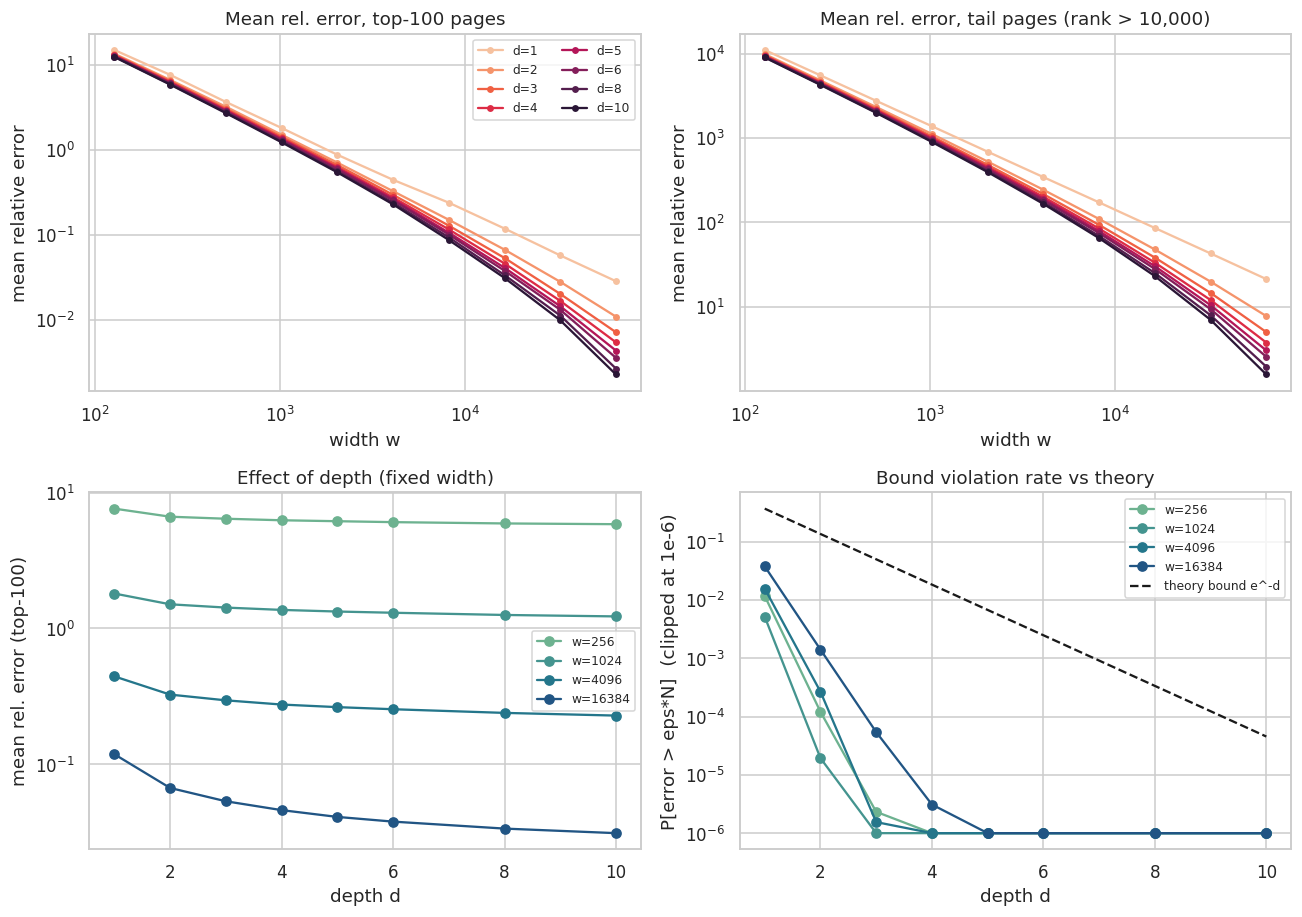

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
pal = sns.color_palette('rocket_r', len(DEPTHS))
for c, d in zip(pal, DEPTHS):
    s = gc_[gc_.depth == d]
    ax[0,0].loglog(s.width, s.rel_head, 'o-', ms=3.5, color=c, label=f'd={d}')
    ax[0,1].loglog(s.width, s.rel_tail, 'o-', ms=3.5, color=c, label=f'd={d}')
ax[0,0].set_title('Mean rel. error, top-100 pages'); ax[0,1].set_title('Mean rel. error, tail pages (rank > 10,000)')
for a in ax[0]: a.set_xlabel('width w'); a.set_ylabel('mean relative error')
ax[0,0].legend(fontsize=8, ncol=2)

for w, c in zip([256, 1024, 4096, 16384], sns.color_palette('crest', 4)):
    s = gc_[gc_.width == w]
    ax[1,0].semilogy(s.depth, s.rel_head, 'o-', color=c, label=f'w={w}')
ax[1,0].set_xlabel('depth d'); ax[1,0].set_ylabel('mean rel. error (top-100)'); ax[1,0].set_title('Effect of depth (fixed width)'); ax[1,0].legend(fontsize=8)

for w, c in zip([256, 1024, 4096, 16384], sns.color_palette('crest', 4)):
    s = gc_[gc_.width == w]
    ax[1,1].semilogy(s.depth, s.viol.clip(lower=1e-6), 'o-', color=c, label=f'w={w}')
dd = np.array(DEPTHS); ax[1,1].semilogy(dd, np.exp(-dd), 'k--', label='theory bound e^-d')
ax[1,1].set_xlabel('depth d'); ax[1,1].set_ylabel('P[error > eps*N]  (clipped at 1e-6)'); ax[1,1].set_title('Bound violation rate vs theory'); ax[1,1].legend(fontsize=8)
savefig('fig06_cms_sweep.png')

CU 비교 실험 시간: 49s


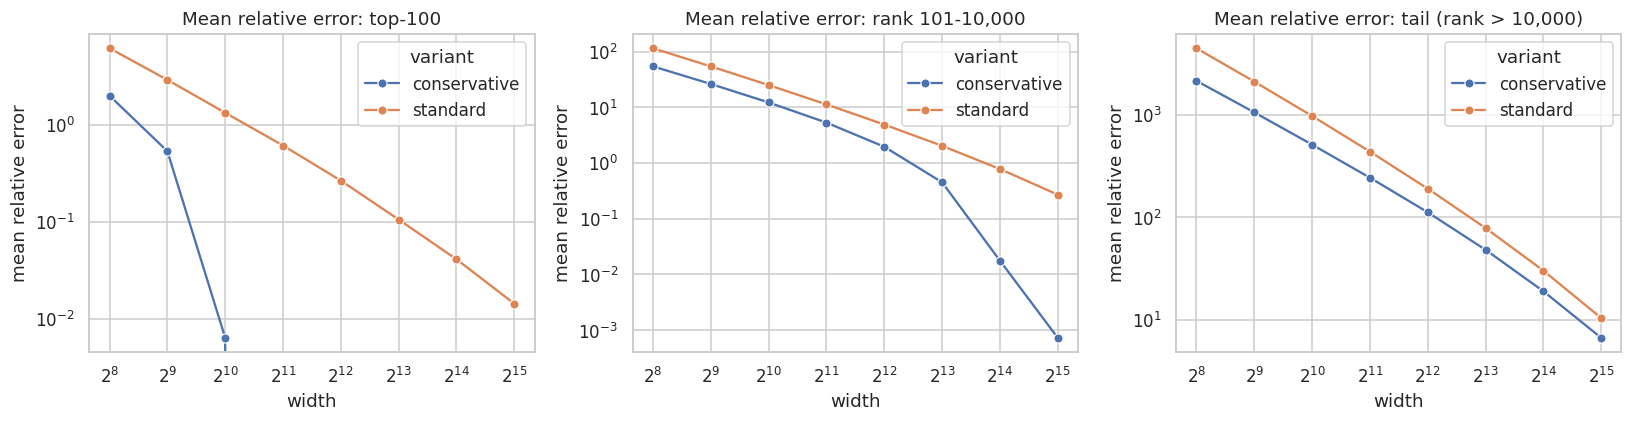

rel_head              rel_tail         
variant conservative standard conservative standard
width                                              
256            1.996    6.165        2,137    4,440
512           0.5344    2.908        1,052    2,100
1024        0.006344    1.332        509.8    969.7
2048               0   0.6116        242.6      436
4096               0   0.2655        111.6    189.6
8192               0   0.1053        48.03    78.34
16384              0  0.04097        18.94    30.08
32768              0  0.01426        6.653    10.38

In [18]:
# Conservative Update(CU) vs 표준 CMS: depth=5 고정, width 변화.  CU 는 순서에 의존하므로 실제 스트림 순서로 순수 Python 루프 실행
curr_index = {k: i for i, k in enumerate(U_curr)}
curr_idx_seq = np.array([curr_index[k] for k in curr_seq], dtype=np.int64)
CU_WIDTHS = [256, 512, 1024, 2048, 4096, 8192, 16384, 32768]
CU_SEEDS = [0, 1, 2]
CU_D = 5
rows = []
t0 = time.perf_counter()
for seed in CU_SEEDS:
    D = cache_Dcurr[seed]
    Dseq = D[curr_idx_seq, :CU_D]
    for w in CU_WIDTHS:
        cols = (Dseq % np.uint32(w)).T.tolist()
        tabs = [[0] * w for _ in range(CU_D)]
        for r in range(N_ROWS):
            c = n_seq[r]
            js = [cols[i][r] for i in range(CU_D)]
            new = min([tabs[i][js[i]] for i in range(CU_D)]) + c
            for i in range(CU_D):
                if tabs[i][js[i]] < new: tabs[i][js[i]] = new
        est_cu = np.min([np.array(tabs[i], dtype=np.float64)[D[:, i] % np.uint32(w)] for i in range(CU_D)], axis=0)
        tabs_std = cms_tables_vec(D, counts, w, CU_D)
        est_std = np.min([tabs_std[i][D[:, i] % np.uint32(w)] for i in range(CU_D)], axis=0)
        for name, e_ in [('standard', est_std), ('conservative', est_cu)]:
            er = e_ - counts; rl = er / counts
            assert (er >= 0).all()
            rows.append(dict(seed=seed, width=w, variant=name, rel_head=rl[head_idx].mean(), rel_torso=rl[torso_idx].mean(),
                             rel_tail=rl[tail_idx].mean(), abs_mean=er.mean()))
print(f'CU 비교 실험 시간: {time.perf_counter()-t0:.0f}s')
df_cu = pd.DataFrame(rows).groupby(['width', 'variant']).mean(numeric_only=True).drop(columns='seed').reset_index()
df_cu.to_csv(os.path.join(OUT_DIR, 'cms_cu_vs_std.csv'), index=False)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, ttl in zip(ax, ['rel_head', 'rel_torso', 'rel_tail'], ['top-100', 'rank 101-10,000', 'tail (rank > 10,000)']):
    sns.lineplot(data=df_cu, x='width', y=col, hue='variant', marker='o', ax=a)
    a.set_xscale('log', base=2); a.set_yscale('log'); a.set_title(f'Mean relative error: {ttl}'); a.set_ylabel('mean relative error')
savefig('fig07_cms_cu.png')
df_cu.pivot(index='width', columns='variant', values=['rel_head', 'rel_tail'])

### 5.3 HyperLogLog: 레지스터 수 `m = 2^p` (p = 4 … 18)
- 이론 표준오차 `1.04/√m` 과 20개 시드의 RMS 상대오차를 비교한다.
- classic 추정기와 improved(Ertl) 추정기를 모두 평가한다. classic 은 `n ≈ 2.5m ~ 5m` 구간에서 편향(bias)이 있다.

In [19]:
PS = list(range(4, 19))
n_true = len(set_curr)
rows = []
for seed in HLL_SEEDS:
    x = hll_x(D_curr if seed == SEED else digest_matrix(U_curr, seed))
    for p in PS:
        reg = hll_registers_vec(x, p)
        for method, f in [('classic', hll_estimate_classic), ('improved', hll_estimate_improved)]:
            rows.append(dict(seed=seed, p=p, m=1 << p, method=method, est=f(reg, p), rel_err=(f(reg, p) - n_true) / n_true))
df_hll = pd.DataFrame(rows)
df_hll.to_csv(os.path.join(OUT_DIR, 'hll_sweep_raw.csv'), index=False)
gh = df_hll.groupby(['p', 'method']).agg(m=('m', 'first'), bias=('rel_err', 'mean'), rms=('rel_err', lambda v: float(np.sqrt(np.mean(np.square(v))))),
                                         max_abs=('rel_err', lambda v: float(np.max(np.abs(v))))).reset_index()
gh['theory_se'] = 1.04 / np.sqrt(gh.m)
gh['bytes_packed'] = np.ceil(gh.m * 6 / 8).astype(int)
gh.to_csv(os.path.join(OUT_DIR, 'hll_sweep.csv'), index=False)
pd.options.display.float_format = '{:,.4f}'.format
gh[gh.method == 'improved'][['p', 'm', 'bytes_packed', 'bias', 'rms', 'max_abs', 'theory_se']]

,p,m,bytes_packed,bias,rms,max_abs,theory_se
1,4,16,12,0.0082,0.3204,0.7668,0.2600
3,5,32,24,0.0405,0.2119,0.5100,0.1838
5,6,64,48,0.0388,0.1267,0.3315,0.1300
7,7,128,96,0.0138,0.0672,0.1736,0.0919
9,8,256,192,0.0063,0.0572,0.1361,0.0650
11,9,512,384,0.0028,0.0302,0.0560,0.0460
13,10,1024,768,0.0077,0.0253,0.0655,0.0325
15,11,2048,1536,0.0035,0.0203,0.0323,0.0230
17,12,4096,3072,0.0059,0.0148,0.0290,0.0163
19,13,8192,6144,0.0037,0.0120,0.0293,0.0115


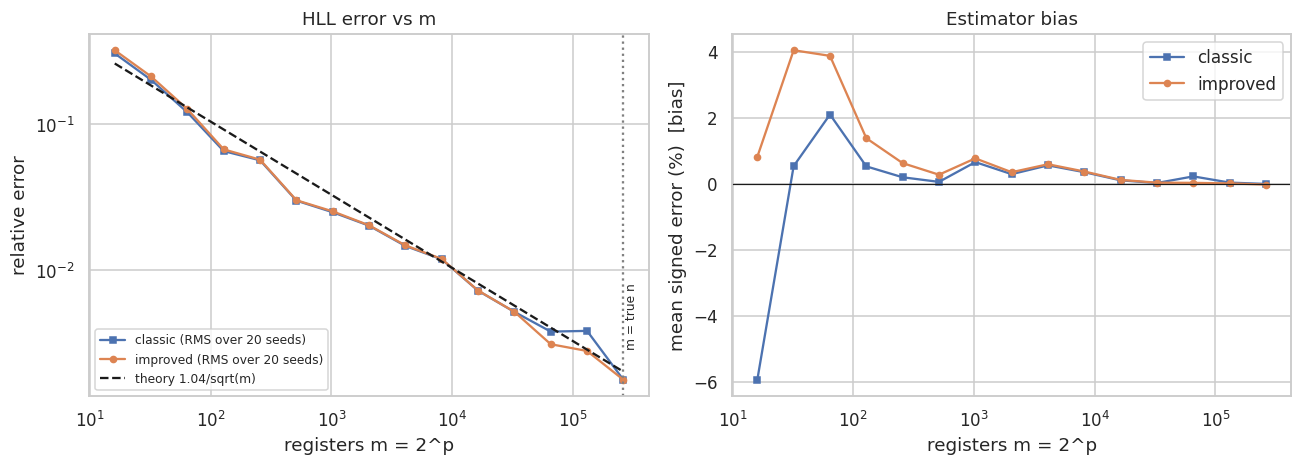

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for meth, mk in [('classic', 's-'), ('improved', 'o-')]:
    s = gh[gh.method == meth]
    ax[0].loglog(s.m, s.rms, mk, ms=4, label=f'{meth} (RMS over {len(HLL_SEEDS)} seeds)')
mm = gh.m.unique(); ax[0].loglog(mm, 1.04/np.sqrt(mm), 'k--', label='theory 1.04/sqrt(m)')
ax[0].axvline(n_true, color='gray', ls=':'); ax[0].text(n_true*1.05, 3e-3, 'm = true n', fontsize=8, rotation=90)
ax[0].set_xlabel('registers m = 2^p'); ax[0].set_ylabel('relative error'); ax[0].legend(fontsize=8); ax[0].set_title('HLL error vs m')
for meth, mk in [('classic', 's-'), ('improved', 'o-')]:
    s = gh[gh.method == meth]; ax[1].semilogx(s.m, s.bias*100, mk, ms=4, label=meth)
ax[1].axhline(0, color='k', lw=.8); ax[1].set_xlabel('registers m = 2^p'); ax[1].set_ylabel('mean signed error (%)  [bias]'); ax[1].legend(); ax[1].set_title('Estimator bias')
savefig('fig08_hll_sweep.png')

### 5.4 파라미터 증가가 처리시간에 미치는 영향 (스트리밍 구현)
정확도가 좋아지는 대신 비용이 어디서 늘어나는지 확인한다. 앞쪽 200,000행, 3회 중앙값.

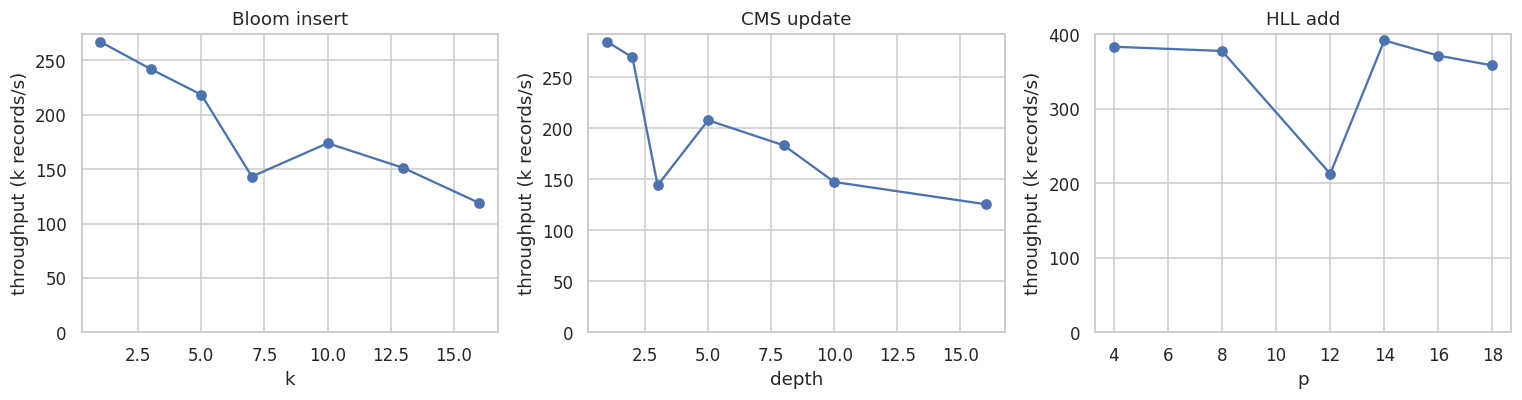

structure,Bloom insert,CMS update,HLL add
value,,,
1,"267,061","284,581",NaN
2,NaN,"269,534",NaN
3,"241,954","144,058",NaN
4,NaN,NaN,"383,050"
5,"218,461","207,800",NaN
7,"143,178",NaN,NaN
8,NaN,"183,200","377,412"
10,"173,889","147,345",NaN
12,NaN,NaN,"212,736"


In [21]:
SUB = 200_000
def run_bloom_k(k):
    b_ = BloomFilter(M_BLOOM, k, SEED)
    for p, c, t, n in itertools.islice(stream_rows(), SUB): b_.add(p + '\t' + c)
def run_cms_d(d):
    c_ = CountMinSketch(CMS_W, d, SEED)
    for p, c, t, n in itertools.islice(stream_rows(), SUB): c_.update(c, n)
def run_hll_p(pp):
    h_ = HyperLogLog(pp, SEED)
    for p, c, t, n in itertools.islice(stream_rows(), SUB): h_.add(c)
rows = []
for k in [1, 3, 5, 7, 10, 13, 16]:
    t, _ = bench(run_bloom_k, k); rows.append(dict(structure='Bloom insert', param='k', value=k, rows_per_s=SUB / t))
for d in [1, 2, 3, 5, 8, 10, 16]:
    t, _ = bench(run_cms_d, d);   rows.append(dict(structure='CMS update', param='depth', value=d, rows_per_s=SUB / t))
for pp in [4, 8, 12, 14, 16, 18]:
    t, _ = bench(run_hll_p, pp);  rows.append(dict(structure='HLL add', param='p', value=pp, rows_per_s=SUB / t))
df_ptime = pd.DataFrame(rows); df_ptime.to_csv(os.path.join(OUT_DIR, 'param_vs_time.csv'), index=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (name, g_) in zip(ax, df_ptime.groupby('structure', sort=False)):
    a.plot(g_.value, g_.rows_per_s / 1e3, 'o-'); a.set_xlabel(g_.param.iloc[0]); a.set_ylabel('throughput (k records/s)'); a.set_title(name); a.set_ylim(0, None)
savefig('fig11_param_vs_time.png')
pd.options.display.float_format = '{:,.0f}'.format
df_ptime.pivot_table(index='value', columns='structure', values='rows_per_s')

## 6. 종합 종합: 메모리–정확도 Trade-off 와 처리량

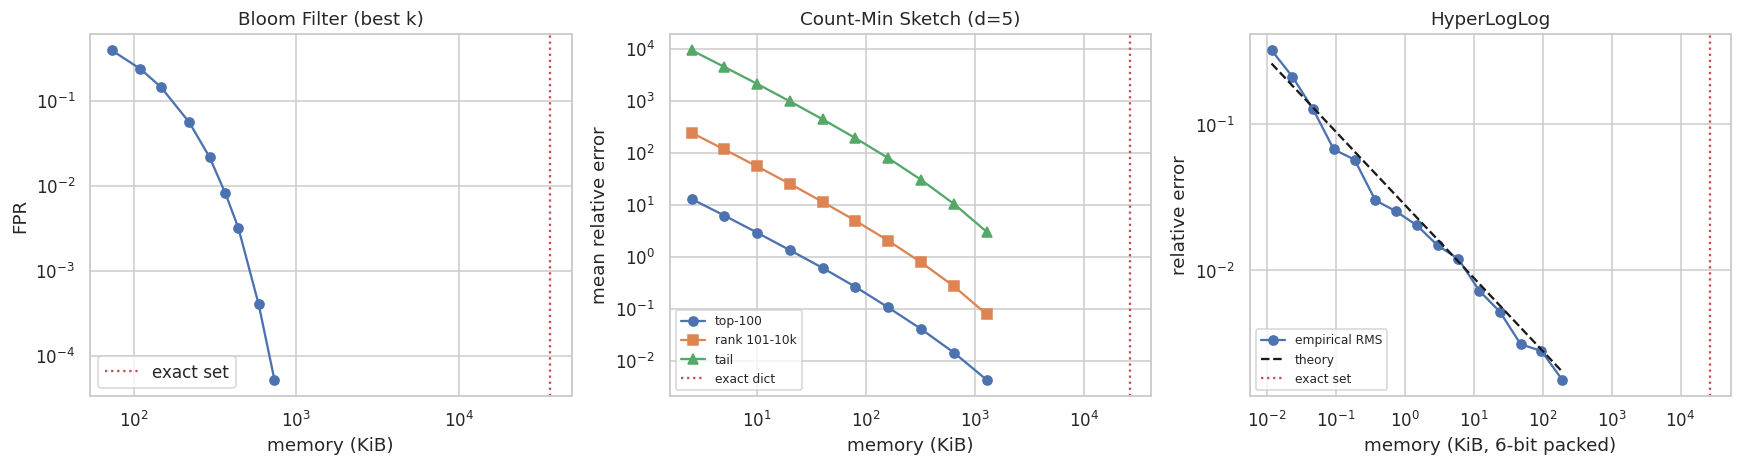

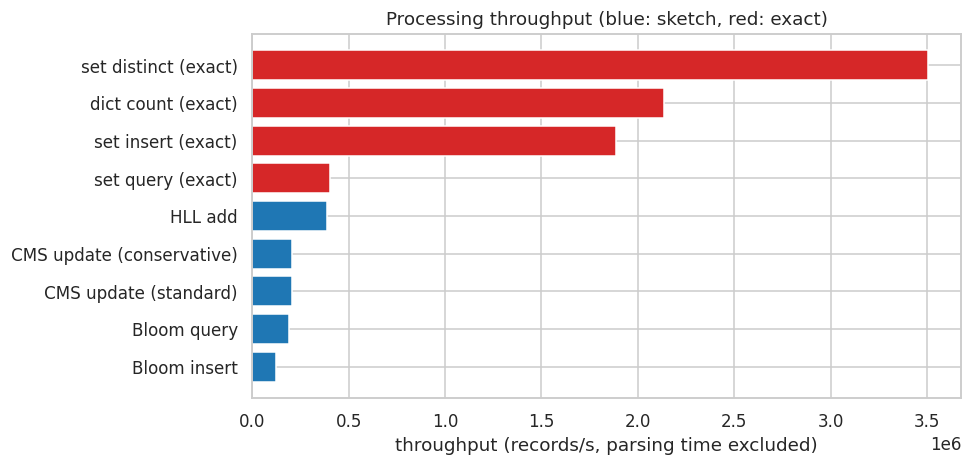

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
# Bloom: bits/elem 별 최적 k 에서의 FPR
ax[0].loglog(bb.bytes/1024, bb.fpr_mean, 'o-'); ax[0].axvline(EXACT_MEM['bloom']/1024, color='r', ls=':', label='exact set')
ax[0].set_xlabel('memory (KiB)'); ax[0].set_ylabel('FPR'); ax[0].set_title('Bloom Filter (best k)'); ax[0].legend()
# CMS: depth 5
s = gc_[gc_.depth == 5]
ax[1].loglog(s.bytes/1024, s.rel_head, 'o-', label='top-100'); ax[1].loglog(s.bytes/1024, s.rel_torso, 's-', label='rank 101-10k')
ax[1].loglog(s.bytes/1024, s.rel_tail, '^-', label='tail')
ax[1].axvline(EXACT_MEM['cms']/1024, color='r', ls=':', label='exact dict'); ax[1].set_xlabel('memory (KiB)'); ax[1].set_ylabel('mean relative error'); ax[1].set_title('Count-Min Sketch (d=5)'); ax[1].legend(fontsize=8)
# HLL: improved
s = gh[gh.method == 'improved']
ax[2].loglog(s.bytes_packed/1024, s.rms, 'o-', label='empirical RMS'); ax[2].loglog(s.bytes_packed/1024, s.theory_se, 'k--', label='theory')
ax[2].axvline(EXACT_MEM['hll']/1024, color='r', ls=':', label='exact set'); ax[2].set_xlabel('memory (KiB, 6-bit packed)'); ax[2].set_ylabel('relative error'); ax[2].set_title('HyperLogLog'); ax[2].legend(fontsize=8)
savefig('fig09_tradeoff.png')

d = df_time.copy()
fig, ax = plt.subplots(figsize=(9, 4.4))
dd = d.sort_values('net_rows_per_s')
ax.barh(dd.structure, dd.net_rows_per_s, color=['tab:red' if g_ == 'exact' else 'tab:blue' for g_ in dd.group])
ax.set_xlabel('throughput (records/s, parsing time excluded)'); ax.set_title('Processing throughput (blue: sketch, red: exact)')
savefig('fig10_throughput.png')

In [23]:
# ---------------- 최종 요약표 + 결과 저장 ----------------
summary = {
  'dataset': ds, 'bloom_main': bloom_main, 'cms_main': cms_main, 'hll_main': hll_main,
  'exact_memory_bytes': EXACT_MEM,
  'sketch_bytes': {'bloom': bf.nbytes, 'cms': cm.nbytes, 'hll_1byte': hl.nbytes, 'hll_packed': hl.nbytes_packed},
  'timing_parse_s': t_parse, 'timing_hash_s': t_hash,
}
with open(os.path.join(OUT_DIR, 'summary.json'), 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=1, default=float)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

saved to results : ['bloom_load.csv', 'bloom_sweep.csv', 'bloom_sweep_raw.csv', 'cms_cu_vs_std.csv', 'cms_sweep.csv', 'cms_sweep_raw.csv', 'figures', 'hll_sweep.csv', 'hll_sweep_raw.csv', 'memory_main.csv', 'param_vs_time.csv', 'summary.json', 'timing_main.csv']
